In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "Object Detection/fashion mnist",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "Object Detection/fashion mnist",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=16
)

class_names = train_ds.class_names

print("Number of Classes:", len(class_names))
print(class_names)

Found 12832 files belonging to 11 classes.
Using 10266 files for training.
Found 12832 files belonging to 11 classes.
Using 2566 files for validation.
Number of Classes: 11
['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']


In [4]:
base = VGG16(
    weights="Object Detection/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5",
    include_top=False,
    input_shape=(224, 224, 3)
)

base.trainable = False

In [5]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,771 (56.39 MB)

 Trainable params: 67,083 (262.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
history = model.fit(
    train_ds.take(100),
    validation_data=test_ds.take(10),
    epochs=3
)

Epoch 1/3


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 ━━━━━━━━━━━━━━━━━━━━ 349s 3s/step - accuracy: 0.6263 - loss: 1.4605 - val_accuracy: 0.6812 - val_loss: 0.9737
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 251s 3s/step - accuracy: 0.8163 - loss: 0.5456 - val_accuracy: 0.7500 - val_loss: 0.7788
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 258s 3s/step - accuracy: 0.8556 - loss: 0.4175 - val_accuracy: 0.7812 - val_loss: 0.7421


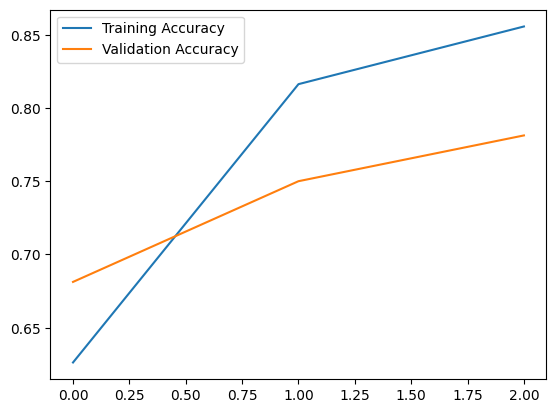

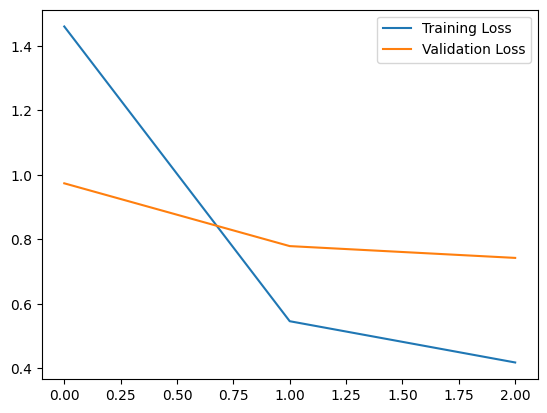

In [7]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

In [8]:
loss, accuracy = model.evaluate(test_ds)

print("Loss:", loss)
print("Accuracy:", accuracy)

161/161 ━━━━━━━━━━━━━━━━━━━━ 301s 2s/step - accuracy: 0.8009 - loss: 0.6261
Loss: 0.6261178255081177
Accuracy: 0.8008573651313782


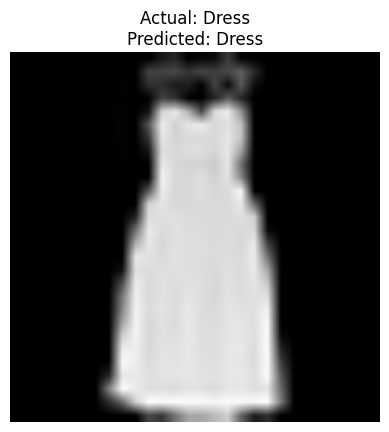

2026-11-02 15:34:22.532278: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [9]:
for images, labels in test_ds.take(1):

    prediction = model.predict(images[:1], verbose=0)
    predicted = prediction.argmax(axis=1)[0]

    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title(f"Actual: {class_names[labels[0]]}\nPredicted: {class_names[predicted]}")
    plt.axis("off")
    plt.show()

In [10]:
# i. Fine tune the top VGG16 layers with a small learning rate.
base.trainable = True
for layer in base.layers[:-6]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds.take(100), validation_data=test_ds.take(10), epochs=1)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/100 ━━━━━━━━━━━━━━━━━━━━ 270s 3s/step - accuracy: 0.9075 - loss: 0.2843 - val_accuracy: 0.7812 - val_loss: 0.6826


In [11]:
loss, accuracy = model.evaluate(test_ds)

print("Fine Tuned Loss:", loss)
print("Fine Tuned Accuracy:", accuracy)

161/161 ━━━━━━━━━━━━━━━━━━━━ 294s 2s/step - accuracy: 0.8114 - loss: 0.6459
Fine Tuned Loss: 0.6459313631057739
Fine Tuned Accuracy: 0.8113795518875122
